# The anonymised export was re-identified: how few columns it takes, counted on one town

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/k-anonymity-check/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/k-anonymity-check/demo.ipynb)

The names were removed. Postcode, date of birth and sex were left in, because a clinic's analysts need them. This
notebook builds a fictional town of 60,000 residents, draws a 3,000-row clinic export from it, and COUNTS how many
rows those three columns point at one person - in the export, and in the whole town - then walks the
generalisation ladder (date to month to year to decade; postcode to sector) to see what each step buys, and runs a
linkage attack with a public register that is complete and one that is missing a fifth of the town. It is not a
redactor (see `pii-redactor`, Day 124); it measures what is left after the redactor is done.

1. The engine
2. How few columns make a row unique
3. The generalisation ladder
4. Unique in the export is not unique in the town
5. The linkage attack, and the register that is wrong
6. k does not protect the value
7. The ceiling
8. The chart
9. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. The town is seeded (`Random(206)`), every resident is
fictional, and every number below matches `evidence.txt` exactly. The study takes a few seconds.

In [1]:
from __future__ import annotations

import random
from collections import Counter, defaultdict
from datetime import date, timedelta
from itertools import combinations, product
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 206


POP_N = 60_000


EXPORT_FRAC = 0.05


K = 5


TODAY = date(2026, 10, 31)


Row = Tuple[int, str, date, str, str]  # person id, postcode, date of birth, sex, diagnosis


AGE_BANDS = [((0, 19), 20), ((20, 39), 27), ((40, 59), 29), ((60, 79), 19), ((80, 95), 5)]


DIAGNOSES = ["routine check", "hypertension", "diabetes", "asthma", "depression", "fracture", "pregnancy", "HIV"]


DIAG_W = [40, 18, 12, 8, 9, 6, 5, 2]


SENSITIVE = {"depression", "HIV"}


POSTCODE_LEVELS: Dict[str, Callable[[str], str]] = {
    "6 digits": lambda p: p,
    "4 digits": lambda p: p[:4],
    "sector (2 digits)": lambda p: p[:2],
    "dropped": lambda p: "*",
}


DOB_LEVELS: Dict[str, Callable[[date], str]] = {
    "full date": lambda d: d.isoformat(),
    "month": lambda d: d.strftime("%Y-%m"),
    "year": lambda d: str(d.year),
    "decade": lambda d: f"{d.year // 10 * 10}s",
    "dropped": lambda d: "*",
}


SEX_LEVELS: Dict[str, Callable[[str], str]] = {"kept": lambda s: s, "dropped": lambda s: "*"}


QI = ("postcode", "date of birth", "sex")


FULL = ("6 digits", "full date", "kept")


def population(n: int = POP_N, seed: int = SEED) -> List[Row]:
    """A fictional town: 20 sectors x 10 sub-areas x 3 buildings = 600 postcodes (SSAABB, so the first four digits
    are the sub-area and the first two the sector) with Zipf-skewed sizes (a tower block holds hundreds, a terrace a
    handful), an age pyramid by band, and a skewed diagnosis mix."""
    rng = random.Random(seed)
    codes = [f"{s:02d}{a:02d}{b:02d}" for s in range(20) for a in range(10) for b in range(3)]
    weights = [1 / (r + 1) ** 0.8 for r in range(len(codes))]
    rng.shuffle(weights)
    bands = [b for b, _ in AGE_BANDS]
    bw = [w for _, w in AGE_BANDS]
    rows: List[Row] = []
    for pid in range(n):
        pc = rng.choices(codes, weights)[0]
        lo, hi = rng.choices(bands, bw)[0]
        age = rng.randint(lo, hi)
        dob = date(TODAY.year - age, 1, 1) + timedelta(days=rng.randrange(365))
        if dob > TODAY:
            dob = TODAY
        sex = rng.choice("MF")
        diag = rng.choices(DIAGNOSES, DIAG_W)[0]
        if diag == "pregnancy" and (sex == "M" or not 18 <= age <= 45):
            diag = "routine check"
        rows.append((pid, pc, dob, sex, diag))
    return rows


def sample(pop: List[Row], frac: float, seed: int = SEED + 1) -> List[Row]:
    rng = random.Random(seed)
    return rng.sample(pop, round(len(pop) * frac))


def key(row: Row, levels: Tuple[str, str, str], use: Tuple[bool, bool, bool] = (True, True, True)) -> Tuple[str, ...]:
    pl, dl, sl = levels
    return (
        POSTCODE_LEVELS[pl](row[1]) if use[0] else "*",
        DOB_LEVELS[dl](row[2]) if use[1] else "*",
        SEX_LEVELS[sl](row[3]) if use[2] else "*",
    )


def profile(export: List[Row], pop: List[Row], levels: Tuple[str, str, str], use=(True, True, True)) -> Dict:
    """One generalisation, measured on the export and projected onto the town it was drawn from."""
    ek = [key(r, levels, use) for r in export]
    ec = Counter(ek)
    pc = Counter(key(r, levels, use) for r in pop)
    n = len(export)
    small = [k for k, c in ec.items() if c < K]
    diag_by_class: Dict[Tuple[str, ...], Counter] = defaultdict(Counter)
    for r, k in zip(export, ek):
        diag_by_class[k][r[4]] += 1
    kept = {k for k, c in ec.items() if c >= K}  # the release after suppressing the classes below K
    homog = {k for k in kept if len(diag_by_class[k]) == 1}
    # attribute disclosure in the release: the share of the class's commonest diagnosis is what an attacker who has
    # placed a person in the class learns about them, k or no k
    near = sum(ec[k] for k in kept if diag_by_class[k].most_common(1)[0][1] / ec[k] >= 0.8)
    sens_confident = sum(
        c for k in kept for d, c in diag_by_class[k].items() if d in SENSITIVE and c / ec[k] >= 0.5
    )
    sens_rows = sum(c for k in kept for d, c in diag_by_class[k].items() if d in SENSITIVE)
    return {
        "levels": levels,
        "classes": len(ec),
        "k_min": min(ec.values()),
        "unique_export": sum(1 for k in ek if ec[k] == 1),
        "unique_pop": sum(1 for k in ek if pc[k] == 1),
        "below_k": sum(ec[k] for k in small),
        "below_k_pop": sum(1 for k in ek if pc[k] < K),
        "released": sum(ec[k] for k in kept),
        "homog_classes": len(homog),
        "homog_rows": sum(ec[k] for k in homog),
        "near_homog_rows": near,
        "sensitive_rows_released": sens_rows,
        "sensitive_confident_rows": sens_confident,
        "n": n,
    }


def qi_subsets(export: List[Row], pop: List[Row]) -> List[Dict]:
    """Every non-empty subset of the three columns at full granularity: how few columns make a row unique."""
    out = []
    for r in (1, 2, 3):
        for idx in combinations(range(3), r):
            use = tuple(i in idx for i in range(3))
            p = profile(export, pop, FULL, use)
            p["columns"] = [QI[i] for i in idx]
            out.append(p)
    return out


def ladder(export: List[Row], pop: List[Row]) -> List[Dict]:
    """All 40 generalisations, most detailed first."""
    out = []
    for pl, dl, sl in product(POSTCODE_LEVELS, DOB_LEVELS, SEX_LEVELS):
        out.append(profile(export, pop, (pl, dl, sl)))
    return out


def first_k_anonymous(lad: List[Dict]) -> List[Dict]:
    """The generalisations that reach k >= K in the export without suppressing anything, most detailed first
    (most classes = least information lost)."""
    ok = [p for p in lad if p["below_k"] == 0]
    return sorted(ok, key=lambda p: -p["classes"])


def k_anonymous_with_suppression(lad: List[Dict], budget: float = 0.05) -> List[Dict]:
    """The generalisations that reach k >= K in the export once at most `budget` of the rows are suppressed,
    most detailed first."""
    ok = [p for p in lad if p["below_k"] <= budget * p["n"]]
    return sorted(ok, key=lambda p: (-p["classes"], p["below_k"]))


def sampling_sweep(pop: List[Row], fracs=(0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0)) -> List[Dict]:
    """Unique in the export vs unique in the town, at full granularity and at sector + year, as the export grows."""
    out = []
    for f in fracs:
        ex = sample(pop, f)
        for lv in (FULL, ("sector (2 digits)", "year", "kept")):
            p = profile(ex, pop, lv)
            out.append(
                {
                    "frac": f,
                    "levels": lv,
                    "n": p["n"],
                    "unique_export_pct": 100 * p["unique_export"] / p["n"],
                    "unique_pop_pct": 100 * p["unique_pop"] / p["n"],
                }
            )
    return out


def linkage(export: List[Row], pop: List[Row], levels: Tuple[str, str, str], coverage: float, seed: int = SEED + 2) -> Dict:
    """An attacker holds a public register (name + the three columns) covering `coverage` of the town and looks
    every export row up by its generalised key. right = exactly one match and it is the person; wrong = exactly one
    match and it is someone else; ambiguous = several matches; none = nobody in the register has that key."""
    rng = random.Random(seed)
    reg = pop if coverage >= 1 else rng.sample(pop, round(len(pop) * coverage))
    by_key: Dict[Tuple[str, ...], List[int]] = defaultdict(list)
    for r in reg:
        by_key[key(r, levels)].append(r[0])
    out = Counter()
    for r in export:
        m = by_key.get(key(r, levels), [])
        if len(m) == 0:
            out["none"] += 1
        elif len(m) > 1:
            out["ambiguous"] += 1
        elif m[0] == r[0]:
            out["right"] += 1
        else:
            out["wrong"] += 1
    return {"levels": levels, "coverage": coverage, "register_n": len(reg), **{k: out[k] for k in ("right", "wrong", "ambiguous", "none")}}


def smallest_postcodes(pop: List[Row], top: int = 3) -> List[Tuple[str, int]]:
    c = Counter(r[1] for r in pop)
    return sorted(c.items(), key=lambda kv: (kv[1], kv[0]))[:top]


def postcode_sizes(pop: List[Row]) -> Dict:
    c = Counter(r[1] for r in pop)
    sizes = sorted(c.values())
    return {"postcodes": len(c), "min": sizes[0], "median": sizes[len(sizes) // 2], "max": sizes[-1]}


def study(pop: Optional[List[Row]] = None) -> Dict:
    pop = pop or population()
    export = sample(pop, EXPORT_FRAC)
    lad = ladder(export, pop)
    ok = first_k_anonymous(lad)
    sup = k_anonymous_with_suppression(lad)
    best = ok[0]
    release = sup[0]
    link_levels = [FULL, ("6 digits", "year", "kept"), ("sector (2 digits)", "year", "kept"), release["levels"], best["levels"]]
    return {
        "pop_n": len(pop),
        "export_n": len(export),
        "sensitive_base": sum(1 for r in export if r[4] in SENSITIVE),
        "postcodes": postcode_sizes(pop),
        "smallest_postcodes": smallest_postcodes(pop),
        "subsets": qi_subsets(export, pop),
        "ladder": lad,
        "k_anonymous": ok,
        "best": best,
        "with_suppression": sup,
        "release": release,
        "sweep": sampling_sweep(pop),
        "linkage": [linkage(export, pop, lv, cov) for lv in link_levels for cov in (1.0, 0.8)],
    }


E = _E()
E.__dict__.update(globals())

SHOW = [
    ("6 digits", "full date", "kept"),
    ("6 digits", "month", "kept"),
    ("6 digits", "year", "kept"),
    ("6 digits", "decade", "kept"),
    ("6 digits", "dropped", "kept"),
    ("4 digits", "year", "kept"),
    ("4 digits", "decade", "kept"),
    ("4 digits", "dropped", "dropped"),
    ("sector (2 digits)", "full date", "kept"),
    ("sector (2 digits)", "month", "kept"),
    ("sector (2 digits)", "year", "kept"),
    ("sector (2 digits)", "decade", "kept"),
    ("sector (2 digits)", "decade", "dropped"),
    ("sector (2 digits)", "dropped", "kept"),
    ("dropped", "year", "kept"),
    ("dropped", "decade", "kept"),
]


def lv(levels) -> str:
    p, d, s = levels
    return f"postcode {p} / dob {d} / sex {s}"


def pct(a: int, n: int) -> str:
    return f"{100 * a / n:.1f}%"


def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    n = r["export_n"]
    pc = r["postcodes"]
    w(
        f"k-anonymity-check evidence  (fictional town of {r['pop_n']:,} residents in {pc['postcodes']} postcodes "
        f"holding {pc['min']} to {pc['max']:,} people, median {pc['median']}; a {n:,}-row clinic export = "
        f"{100 * n / r['pop_n']:g}% of the town; three quasi-identifiers: postcode, date of birth, sex; "
        f"k = {E.K}; seeded Random({E.SEED}), every person fictional)"
    )
    w("")
    w("1. How few columns make a row unique (full granularity; 'in the town' = no other resident shares the key)")
    w(f"{'columns':<36} {'unique in export':>17} {'unique in town':>15} {'classes':>8}")
    for p in r["subsets"]:
        w(
            f"{' + '.join(p['columns']):<36} {p['unique_export']:>7} ({pct(p['unique_export'], n):>6}) "
            f"{p['unique_pop']:>6} ({pct(p['unique_pop'], n):>6}) {p['classes']:>8}"
        )
    w("")
    w(f"2. The generalisation ladder ({len(SHOW)} of {len(r['ladder'])} combinations; all 40 in results.json)")
    w(f"{'generalisation':<58} {'classes':>7} {'k_min':>5} {'uniq export':>11} {'uniq town':>9} {'<5 export':>9} {'<5 town':>7}")
    by = {tuple(p["levels"]): p for p in r["ladder"]}
    for levels in SHOW:
        p = by[levels]
        w(
            f"{lv(levels):<58} {p['classes']:>7} {p['k_min']:>5} {p['unique_export']:>11} {p['unique_pop']:>9} "
            f"{p['below_k']:>9} {p['below_k_pop']:>7}"
        )
    ok = r["k_anonymous"]
    b = r["best"]
    rel = r["release"]
    w(
        f"k >= {E.K} in the export with nothing suppressed: {len(ok)} of {len(r['ladder'])} combinations, the finest "
        f"= {lv(b['levels'])} ({b['classes']} classes)"
    )
    w(
        f"k >= {E.K} after suppressing at most 5% of rows: finest = {lv(rel['levels'])} ({rel['classes']} classes, "
        f"{rel['below_k']} rows suppressed, {rel['released']:,} released)"
    )
    w("")
    w("3. Unique in the export vs unique in the town, as the export grows (two keys)")
    w(f"{'export':>8} {'rows':>7} {'full key: export':>17} {'town':>7} {'sector+year+sex: export':>24} {'town':>7}")
    sw = r["sweep"]
    fr = sorted({s["frac"] for s in sw})
    for f in fr:
        a = next(s for s in sw if s["frac"] == f and tuple(s["levels"]) == E.FULL)
        c = next(s for s in sw if s["frac"] == f and tuple(s["levels"]) != E.FULL)
        w(
            f"{100 * f:>7g}% {a['n']:>7,} {a['unique_export_pct']:>16.1f}% {a['unique_pop_pct']:>6.1f}% "
            f"{c['unique_export_pct']:>23.1f}% {c['unique_pop_pct']:>6.2f}%"
        )
    sy = by[("sector (2 digits)", "year", "kept")]
    w(
        f"two attackers at sector+year+sex on the {n:,}-row export: one who knows the person IS a patient needs only "
        f"export-uniqueness and re-identifies {sy['unique_export']:,}; a stranger needs town-uniqueness and "
        f"re-identifies {sy['unique_pop']}"
    )
    w("")
    w("4. Linkage with a public register (name + the three columns), complete and missing 20% of the town")
    w(f"{'generalisation':<58} {'register':>8} {'right':>6} {'wrong':>6} {'ambiguous':>9} {'none':>5}")
    for k in r["linkage"]:
        w(
            f"{lv(k['levels']):<58} {100 * k['coverage']:>7g}% {k['right']:>6} {k['wrong']:>6} "
            f"{k['ambiguous']:>9} {k['none']:>5}"
        )
    w("")
    w(f"5. k does not protect the value (baseline: {pct(r['sensitive_base'], n)} of export rows carry a sensitive diagnosis)")
    w(
        f"the release ({lv(rel['levels'])}): {rel['homog_classes']} classes where everyone shares one diagnosis "
        f"({rel['homog_rows']} rows); {rel['near_homog_rows']} rows in classes where one diagnosis is >= 80%; "
        f"{rel['sensitive_confident_rows']} of {rel['sensitive_rows_released']} sensitive rows sit in a class that "
        f"makes an attacker >= 50% sure of it"
    )
    hot = [p for p in r["ladder"] if p["sensitive_confident_rows"] > 0]
    w(f"generalisations whose k >= {E.K} release leaves an attacker >= 50% sure of a sensitive diagnosis: {len(hot)} of {len(r['ladder'])}")
    for p in sorted(hot, key=lambda p: -p["sensitive_confident_rows"])[:4]:
        w(
            f"   {lv(p['levels']):<56} {p['sensitive_confident_rows']:>3} rows ({p['homog_classes']} homogeneous classes, "
            f"{p['below_k']} suppressed)"
        )
    w("")
    w("6. The ceiling")
    w(
        "smallest postcodes            : "
        + ", ".join(f"{c} ({k} residents)" for c, k in r["smallest_postcodes"])
        + " - a six-digit postcode can never be hidden among many"
    )
    w(
        f"export k is not town k        : at sector+year+sex the export has k_min {sy['k_min']} and {sy['below_k']:,} rows "
        f"below {E.K}; the town has {sy['below_k_pop']} below {E.K}. The right-hand column needs the town, which is "
        "not in the file"
    )
    full = by[E.FULL]
    w(
        f"two columns are already enough: postcode + date of birth make {r['subsets'][3]['unique_pop']:,} "
        f"of {n:,} rows unique in the town; adding sex makes {full['unique_pop']:,}"
    )
    return out


def main() -> None:
    r = E.study()
    json.dump({"main": r}, open("results.json", "w"), indent=1, ensure_ascii=False, default=str)
    open("evidence.txt", "w").write("\n".join(lines(r)) + "\n")
    print("\n".join(lines(r)))

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

k-anonymity-check evidence  (fictional town of 60,000 residents in 600 postcodes holding 15 to 4,438 people, median 46; a 3,000-row clinic export = 5% of the town; three quasi-identifiers: postcode, date of birth, sex; k = 5; seeded Random(206), every person fictional)


## 2. How few columns make a row unique

Two. The postcode alone makes no resident unique in the town (the smallest postcode holds 15 people), and sex alone
makes none; the date of birth alone already makes 498 of the 3,000 exported residents the only person in town born
that day. Postcode + date of birth make 2,932 of 3,000 unique in the whole town, and adding sex lifts that to
2,964. The third column added 32 rows; the second added 2,434.

In [3]:
print("\n".join(section(1)))

How few columns make a row unique (full granularity; 'in the town' = no other resident shares the key)
columns                               unique in export  unique in town  classes
postcode                                 114 (  3.8%)      0 (  0.0%)      525
date of birth                           2687 ( 89.6%)    498 ( 16.6%)     2841
sex                                        0 (  0.0%)      0 (  0.0%)        2
postcode + date of birth                2994 ( 99.8%)   2932 ( 97.7%)     2997
postcode + sex                           353 ( 11.8%)      0 (  0.0%)      848
date of birth + sex                     2851 ( 95.0%)   1186 ( 39.5%)     2923
postcode + date of birth + sex          3000 (100.0%)   2964 ( 98.8%)     3000


## 3. The generalisation ladder

Forty ways to coarsen the three columns. Year of birth with the full postcode still leaves 2,487 export rows unique
and 1,097 unique in the town; the decade still leaves 111 town-unique rows. Only 6 of the 40 generalisations reach
k = 5 in the export without suppressing a row, and the finest of them is sector + sex, 40 classes, with the date of
birth gone entirely. Allowing 5% of rows to be suppressed, the finest is sector + decade with sex dropped: 199
classes, 51 rows suppressed.

In [4]:
print("\n".join(section(2)))

The generalisation ladder (16 of 40 combinations; all 40 in results.json)
generalisation                                             classes k_min uniq export uniq town <5 export <5 town
postcode 6 digits / dob full date / sex kept                  3000     1        3000      2964      3000    2999
postcode 6 digits / dob month / sex kept                      2976     1        2952      2353      3000    2941
postcode 6 digits / dob year / sex kept                       2707     1        2487      1097      2983    2123
postcode 6 digits / dob decade / sex kept                     1950     1        1494       111      2436     763
postcode 6 digits / dob dropped / sex kept                     848     1         353         0      1257       0
postcode 4 digits / dob year / sex kept                       2630     1        2349       532      2978    1809
postcode 4 digits / dob decade / sex kept                     1601     1        1008         9      2240     110
postcode 4 digits / do

## 4. Unique in the export is not unique in the town

At sector + year + sex, 40.1% of the 3,000 export rows are unique in the export and 0.03% - one row - is unique in
the town. The export's own uniqueness is an upper bound, and it is loose until the export is most of the town. Which
bound matters depends on who is looking: an insider who knows the person is a patient needs only the export, and
re-identifies 1,203 people; a stranger needs the town, and re-identifies 1. At the full key both numbers are the
same, 98.8%, because the key is finer than the town.

In [5]:
print("\n".join(section(3)))

Unique in the export vs unique in the town, as the export grows (two keys)
  export    rows  full key: export    town  sector+year+sex: export    town
      1%     600            100.0%   98.2%                    78.5%   0.00%
      2%   1,200            100.0%   98.8%                    65.8%   0.00%
      5%   3,000            100.0%   98.8%                    40.1%   0.03%
     10%   6,000             99.8%   98.6%                    19.1%   0.03%
     20%  12,000             99.8%   98.7%                     6.0%   0.07%
     50%  30,000             99.4%   98.8%                     0.7%   0.07%
    100%  60,000             98.8%   98.8%                     0.1%   0.07%
two attackers at sector+year+sex on the 3,000-row export: one who knows the person IS a patient needs only export-uniqueness and re-identifies 1,203; a stranger needs town-uniqueness and re-identifies 1


## 5. The linkage attack, and the register that is wrong

An attacker holds a public register with names and the same three columns. Complete, it re-identifies exactly the
town-unique rows - 2,964 - and is never wrong. Missing 20% of the town, at the full key it loses 599 rows to
"not in register" and is wrong once; at year of birth it is right 977 times and wrong 101 times, each of those a
confident match to the wrong resident, because the right one is not in the register and someone else shares the
key. At sector + year it is wrong more often than right.

In [6]:
print("\n".join(section(4)))

Linkage with a public register (name + the three columns), complete and missing 20% of the town
generalisation                                             register  right  wrong ambiguous  none
postcode 6 digits / dob full date / sex kept                   100%   2964      0        36     0
postcode 6 digits / dob full date / sex kept                    80%   2372      1        28   599
postcode 6 digits / dob year / sex kept                        100%   1097      0      1903     0
postcode 6 digits / dob year / sex kept                         80%    977    101      1665   257
postcode sector (2 digits) / dob year / sex kept               100%      1      0      2999     0
postcode sector (2 digits) / dob year / sex kept                80%      3      4      2993     0
postcode sector (2 digits) / dob decade / sex dropped          100%      0      0      3000     0
postcode sector (2 digits) / dob decade / sex dropped           80%      0      0      3000     0
postcode sector (2 dig

## 6. k does not protect the value

k is about the quasi-identifiers; the diagnosis is a fourth column that k never looks at. In the 199-class release
no class is homogeneous, but 31 rows sit in classes where one diagnosis is at least 80% of the class. Ten of the 40
generalisations produce a k = 5 release in which an attacker who places a person in their class is at least 50%
sure of a sensitive diagnosis (baseline 11.7%).

In [7]:
print("\n".join(section(5)))

k does not protect the value (baseline: 11.7% of export rows carry a sensitive diagnosis)
the release (postcode sector (2 digits) / dob decade / sex dropped): 0 classes where everyone shares one diagnosis (0 rows); 31 rows in classes where one diagnosis is >= 80%; 0 of 345 sensitive rows sit in a class that makes an attacker >= 50% sure of it
generalisations whose k >= 5 release leaves an attacker >= 50% sure of a sensitive diagnosis: 10 of 40
   postcode 4 digits / dob dropped / sex kept                13 rows (2 homogeneous classes, 477 suppressed)
   postcode sector (2 digits) / dob decade / sex kept         8 rows (2 homogeneous classes, 364 suppressed)
   postcode sector (2 digits) / dob year / sex dropped        6 rows (2 homogeneous classes, 2350 suppressed)
   postcode 6 digits / dob decade / sex kept                  4 rows (1 homogeneous classes, 2436 suppressed)


## 7. The ceiling

The export's k is not the town's k, and the town is not in the file. At sector + year + sex the export has 2,740
rows below k = 5 and the town has 52; neither number can be read off the other. And a six-digit postcode that
holds 15 residents cannot hide anyone, whatever is done to the other columns.

In [8]:
print("\n".join(section(6)))

The ceiling
smallest postcodes            : 040800 (15 residents), 060001 (16 residents), 160000 (16 residents) - a six-digit postcode can never be hidden among many
export k is not town k        : at sector+year+sex the export has k_min 1 and 2,740 rows below 5; the town has 52 below 5. The right-hand column needs the town, which is not in the file
two columns are already enough: postcode + date of birth make 2,932 of 3,000 rows unique in the town; adding sex makes 2,964


## 8. The chart

The full figure, with one row walked down the ladder, is `audit.png` (built by `make_chart.py`).

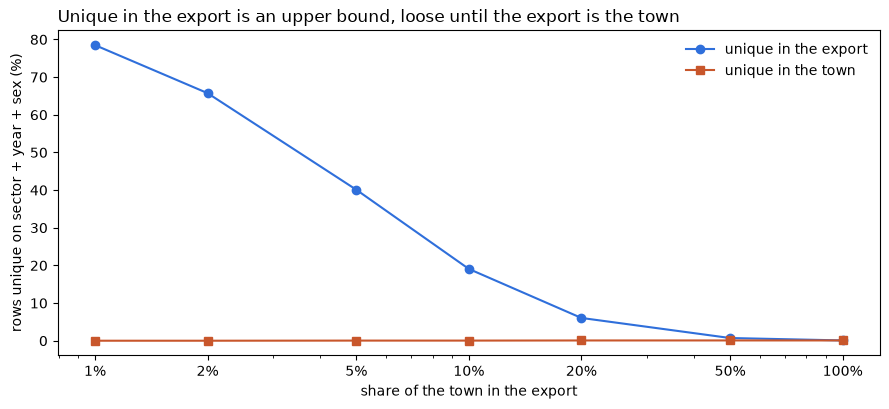

In [9]:
sw = [s for s in r["sweep"] if tuple(s["levels"]) == ("sector (2 digits)", "year", "kept")]
xs = [100 * s["frac"] for s in sw]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(xs, [s["unique_export_pct"] for s in sw], "-o", color="#2f6fdb", label="unique in the export")
ax.plot(xs, [s["unique_pop_pct"] for s in sw], "-s", color="#c8562b", label="unique in the town")
ax.set_xscale("log")
ax.set_xticks(xs, [f"{x:g}%" for x in xs])
ax.set_xlabel("share of the town in the export")
ax.set_ylabel("rows unique on sector + year + sex (%)")
ax.set_title("Unique in the export is an upper bound, loose until the export is the town", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Two columns do it: postcode + date of birth make 97.7% of the exported residents unique in a town of 60,000.
- Of 40 generalisations, 6 reach k = 5 without suppression and all of them drop the date of birth or the postcode
  to its sector; with 5% suppression, sector + decade.
- "Unique in the export" is what an insider needs and an upper bound on what a stranger needs; the two differ by a
  factor of 1,000 at a coarse key and not at all at a fine one.
- A linkage register that is incomplete does not fail quietly: it names the wrong person, confidently, 101 times.
- k says nothing about the diagnosis column; count the share of each class's commonest value before releasing.

## 9. Try your own

In [10]:
# pop = population()
# export = sample(pop, 0.05)
# for levels in [("6 digits", "year", "kept"), ("sector (2 digits)", "decade", "kept"), ("4 digits", "dropped", "kept")]:
#     p = profile(export, pop, levels)
#     print(levels, "classes", p["classes"], "unique export", p["unique_export"], "unique town", p["unique_pop"],
#           "below k", p["below_k"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version measures your
own export's columns at any generalisation: `pip install -r requirements.txt && streamlit run app.py`.